# 04 First order conduit stats

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from os.path import exists, split, join
from os import makedirs
from tqdm import tqdm

import base.geometry as geom

from base.utils import list_all_centrelines, return_centreline_parametrisation

Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.


In [2]:
# change here the path to the repository of karst catalogue
data_repository = "F:/ScanLeica/data_paper/KarstConduitCatalogue" 
centreline_filepaths = list_all_centrelines(data_repository)

We now select a specific cave passage and read out the section information, including the geometric descriptors.

In [3]:
idx = 17

sections_directory = join(split(centreline_filepaths[idx])[0], "sections")
stub = len("_centreline.txt")
thecavepassage = split(centreline_filepaths[idx])[1][:-stub]

Now we can find and load the geometric descriptors calculated on the relevant sections. 

In [4]:
descriptors_filepath = join(split(centreline_filepaths[idx])[0], "section_descriptors.txt")
conduit_descriptors = np.loadtxt(descriptors_filepath, delimiter=" ", skiprows=1)
with open(descriptors_filepath, "r") as f:
    header = f.readline()[2:-1].split(",")
    f.close()

Since we have twenty descriptors, we can have a look at all descriptors in a matrix of histograms. 

We let $\Omega$ be the section object, with an outer contour called $p$ after `doi.org/10.1021/acscatal.5b02628`

$A = card(x) \mid x \in \Omega$

$P = \sum_{x \in p}{V(x)}, \text{V local weighting function}$

$L = max\left\Vert x_1 - x_2 \right\Vert x_1 \in p, x_2 \in p, x1 \neq x_2$

$r_{min}  = min\left\Vert x - c \right\Vert \mid x \in p$

$r_{max}  = max\left\Vert x - c \right\Vert \mid x \in p$

$r_{ave} = \frac{1}{card(p)} \sum_{x \in p}{\left\Vert x - c \right\Vert} $

$D_{H} = \frac{4A}{P}$

$\gamma_1 = \frac{r_{min}}{r_{max}}$

$\gamma_2 = \frac{P^2}{A}$

$\gamma_c = \frac{P}{2 \sqrt{\pi A}}$

$\gamma_3 = \frac{r_{max} - r_{min}}{r_{max}}$

$\delta_{inscribed} = \frac{\pi r_{min}^2}{A}$

$\delta_{circumscribed} = \frac{\pi r_{max}^2}{A}$

$E = \frac{4}{\pi} \frac{A}{{r_{ave}}^2}$

$d_{iso} = \frac{4 \pi A}{p^2}$

$\gamma_M = \frac{4}{\pi} \frac{A}{L^2}$

$\sigma^2_{circ} = \frac{\sum_{x \in \Omega}{(\left \Vert x - c \right \Vert -r_{ave})^2}}{Ar_{ave}^2}$

$S = \frac{card(x_1)}{card(x_2)} \mid x_1 \in \Omega, x_2 \in \mathcal{C}(\Omega)$

In [5]:
def plotDH(sections,  idx, ax):
    dh = 4* geom.compute_ngon_area(sections[idx]) / geom.compute_ngon_perimeter(sections[idx])
    xi = np.linspace(0, 2*np.pi, 100)
    # upper semi-circle
    ax.fill(np.vstack([dh/2*np.cos(xi), dh/2*np.sin(xi)]).T, alpha = 0.66, color = "grey", edgecolor=None)
    return ax

def plotCHull(sections,  idx, ax):
    chull = geom.compute_convex_hull(sections[idx])

    ax.fill(chull[:,[0, 1]].T, zorder = -10, color = "C1")
    return ax

In [6]:
def plotDescriptor(sections, descriptors, header, col, ax, ax_hist, ax_inset1, ax_inset2, inset_size = 10, last = False):
    # coordinates for plotting in the insets
    descriptor_ok = descriptors[:, col]
    xi_ok = descriptors[:, -1]
    # indices to integers. 

    # indices of max and min descriptor value 
    argmax_descriptor = np.argmax(descriptor_ok)
    argmin_descriptor = np.argmin(descriptor_ok)

    _min = min(descriptor_ok)
    _max = max(descriptor_ok)
    _range = _max - _min
    
    # Plotting along the curviline
    ax.plot(xi_ok, descriptor_ok, "-o", markersize = 4)
    ax.scatter(xi_ok[argmax_descriptor], descriptor_ok[argmax_descriptor], color = "white",  edgecolor = "firebrick", zorder = 100, s = 50, marker = "D")
    ax.scatter(xi_ok[argmin_descriptor], descriptor_ok[argmin_descriptor], color = "white", edgecolor = "dodgerblue", zorder = 100, s = 50, marker = "D")
    ax.set_ylim(_min -0.1*_range, _max +0.1*_range)
    
    # Plotting the histogram
    ax_hist.hist(descriptor_ok, density = True, orientation = "horizontal", bins = int(1+ np.log2(len(descriptor_ok))))

    # Plotting the insets
    ax_inset1.plot(*sections[argmax_descriptor][:,[0, 1]].T,  color = "firebrick")
    ax_inset2.plot(*sections[argmin_descriptor][:,[0, 1]].T, color = "dodgerblue")

    # if hydraulic diameter. 
    if (header[col] == "hydraulic_diameter") or (header[col] == "circularity"): 
        plotDH(sections, argmax_descriptor, ax_inset1)
        plotDH(sections, argmin_descriptor, ax_inset2)
        
    elif header[col] == "solidity":
        plotCHull(sections, argmax_descriptor, ax_inset1)
        plotCHull(sections, argmin_descriptor, ax_inset2)
   
    # make cosmetic ajustments to insets 
    for ax_inset in (ax_inset1, ax_inset2):
        ax_inset.set_aspect("equal")
        ax_inset.tick_params(top=True, right=True, left = False, bottom= False)
        ax_inset.xaxis.tick_top()
        ax_inset.yaxis.tick_right()
        ax_inset.yaxis.set_label_position("right")
        ax_inset.set_ylabel("z [m]")
        ax_inset.set_xlim(-inset_size, inset_size)
        ax_inset.set_ylim(-inset_size, inset_size)


        tick_pos = np.round(inset_size*2 /3)
        ax_inset.set_xticks([-tick_pos,0,tick_pos])
        ax_inset.set_yticks([-tick_pos,0,tick_pos])
    
    ax.grid(lw = 0.5, ls="--")

    for spine in ["top","right"]:
        ax.spines[spine].set_visible(False)
        ax_hist.spines[spine].set_visible(False)

    # annotate with some interesting trivia
    if last == True:
        ax.set_xlabel("Coordinate along centreline [m]")

In [7]:
from matplotlib.gridspec import GridSpec

In [8]:
centreline_filepaths = list_all_centrelines(data_repository)
centreline_filepath = centreline_filepaths[idx]
assert exists(centreline_filepath)
centreline = np.loadtxt(centreline_filepath, skiprows=1)

In [9]:
interpolated_centreline, curvilinear_coords, normed_vectors = return_centreline_parametrisation(centreline, dt=1)

In [10]:
sections = [np.loadtxt(join(sections_directory, f"s{c}.txt"), skiprows=1) for c in range(len(normed_vectors))]

In [11]:
sections2d = [geom.to2D(section, nP) for section, nP in zip(sections, normed_vectors)]

['area', 'hydraulic diameter', 'convex hull solidity']
0
7
14


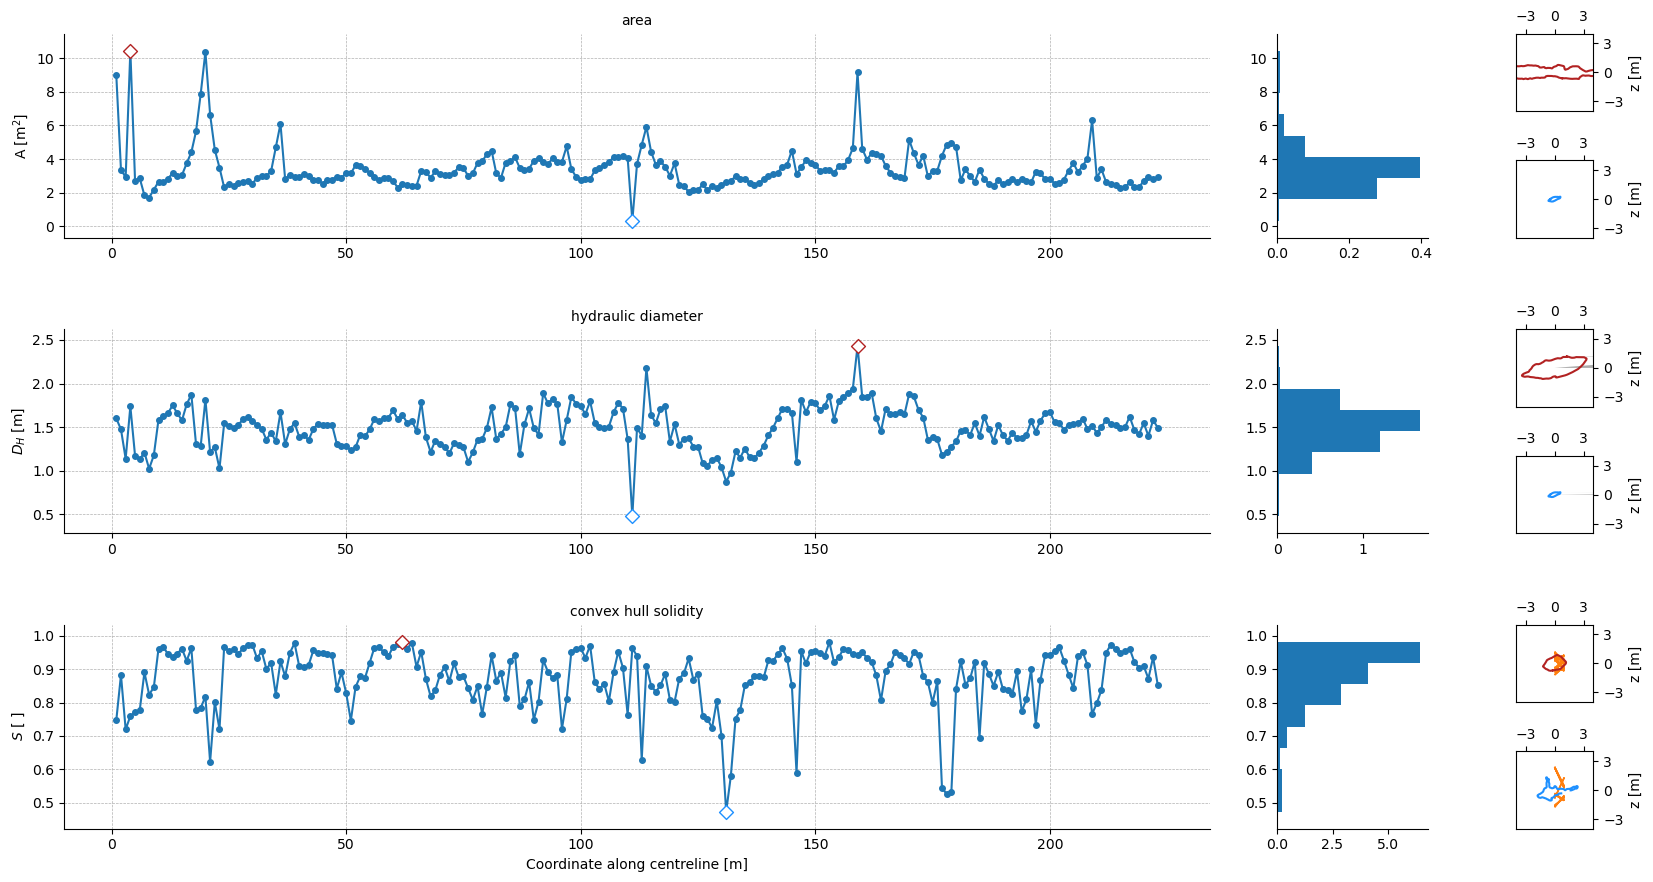

In [12]:
fig = plt.figure(figsize = (20, 18))

gs = GridSpec(33, 50)
attributes = [0, 5, 4]

labels = [geom.DESCRIPTOR_MAP[header[elem]]["name"] for elem in attributes]
units = [geom.DESCRIPTOR_MAP[header[elem]]["unit"] for elem in attributes]
abbrs = [geom.DESCRIPTOR_MAP[header[elem]]["abbr"] for elem in attributes]


print(labels)
descriptors = {}

for n, (col, label, unit, abbr) in enumerate(zip(attributes, labels, units, abbrs)):
    i = 7*n
    print(i)
    ax = fig.add_subplot(gs[i:i+5, :37])
    ax.set_ylabel(f"{abbr} [{unit}]")
    ax.set_title(label, fontsize =10)
    
    ax_hist = fig.add_subplot(gs[i:i+5, 39:44], sharey = ax)
    
    ax_inset1 = fig.add_subplot(gs[i:i+2, 46:])
    ax_inset2 = fig.add_subplot(gs[i+3:i+5, 46:], sharex = ax_inset1, sharey = ax_inset1)
    
    last = False
    if n == len(attributes) -1:
        last = True
    
    plotDescriptor(sections2d, conduit_descriptors,header, col, ax, ax_hist, ax_inset1, ax_inset2, inset_size=4, last = last)


In [13]:
fig = plt.figure()



<Figure size 640x480 with 0 Axes>

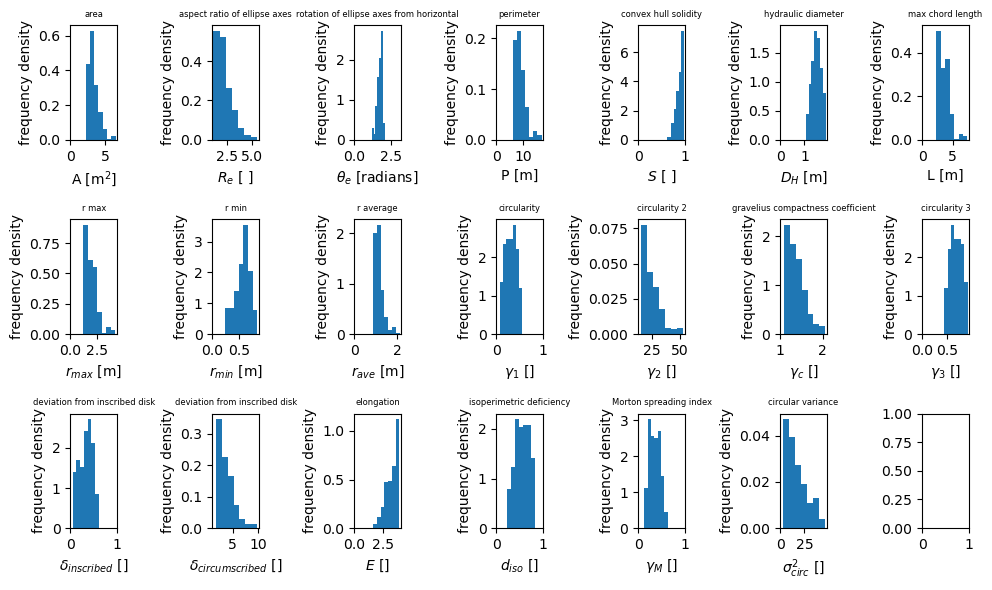

In [14]:
fig, axes = plt.subplots(3, 7, figsize = (10, 6))

for c, (descriptor, ax) in enumerate(zip(header[:-1], axes.flatten())):
    data = conduit_descriptors[:, c]
    

    too_small_areas = conduit_descriptors[:, 0] < 1

    bins = np.linspace(*np.quantile(data, [0.025, 0.975]), int(1+np.log2(len(data))))

    ax.hist(data[~too_small_areas], bins= bins, density=True)

    ax.set_xlim(*geom.DESCRIPTOR_MAP[descriptor]["bounds"])
    ax.set_ylabel("frequency density")
    ax.set_xlabel(f"{geom.DESCRIPTOR_MAP[descriptor]['abbr']} [{geom.DESCRIPTOR_MAP[descriptor]['unit']}]")
    ax.set_title(f"{geom.DESCRIPTOR_MAP[descriptor]['name']}", fontsize=6)

plt.tight_layout()
plt.savefig("./temp/fauxMonnayeursHistograms.png")
plt.show()

In [15]:
centreline = np.loadtxt(centreline_filepaths[idx], skiprows=1)
interpolated_centreline, curvilinear_coords, normed_vectors = return_centreline_parametrisation(centreline)

In [16]:
sections = [np.loadtxt(join(sections_directory, f"s{c}.txt"), skiprows=1) for c in range(len(normed_vectors))]

In [17]:
fill_curves = np.array([np.loadtxt(join(sections_directory, f"fill_curve_s{c}.txt"), skiprows=1) for c in range(len(normed_vectors))])

In [18]:
diameters_fill_curves = 4*fill_curves[:, 1:-1, 1] / fill_curves[:, 1:-1, 2]

In [19]:
header

['area',
 'ellipse_aspect_ratio',
 'ellipse_rotation',
 'perimeter',
 'solidity',
 'hydraulic_diameter',
 'max_chord_length',
 'rmax',
 'rmin',
 'r_average',
 'circularity',
 'circularity2',
 'gravelius_compactness',
 'circularity3',
 'deviation_from_inscribed_disk',
 'deviation_from_circumscribed_disk',
 'elongation',
 'isoperimetric_deficiency',
 'morton_spreading_index',
 'circular_variance',
 'curvilinear_coord']

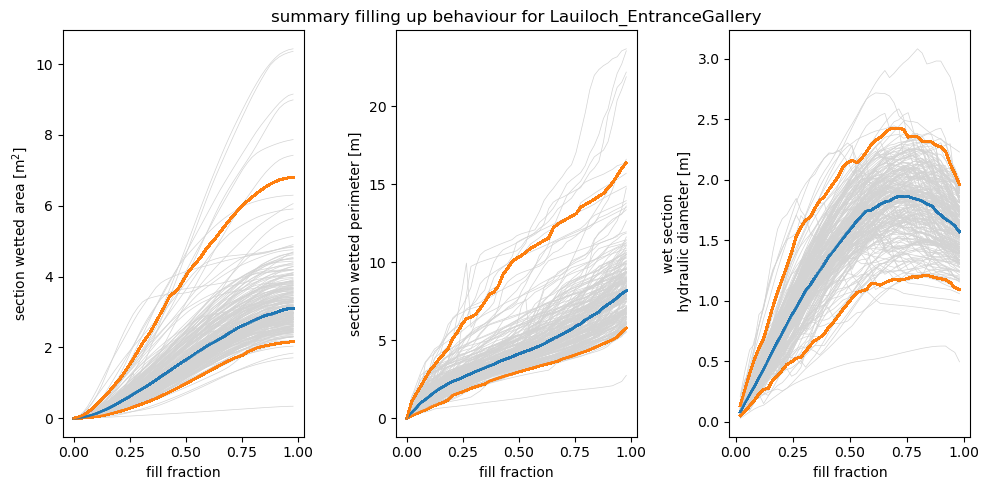

In [20]:
fig, axes = plt.subplots(1, 3, figsize = (10, 5))

for fill_curve in fill_curves:
    diameters_fill_curve = 4*fill_curve[1:-1, 1] / fill_curve[1:-1, 2]

    axes[0].plot(*fill_curve[:-1, [0, 1]].T, color = "lightgrey", lw = 0.5)
    axes[1].plot(*fill_curve[:-1, [0, 2]].T, color = "lightgrey", lw = 0.5)
    axes[2].plot(fill_curve[1:-1, 0], diameters_fill_curve, color = "lightgrey", lw = 0.5)
    
    for q, color in zip((0.025, 0.5, 0.975), ("C1", "C0", "C1")):
        axes[0].plot(fill_curve[:-1, 0], np.quantile(fill_curves[:, :-1, 1],q,  axis =0), color = color, label = "")
        axes[1].plot(fill_curve[:-1, 0], np.quantile(fill_curves[:, :-1, 2],q,  axis =0), color = color)
        axes[2].plot(fill_curve[1:-1, 0], np.quantile(diameters_fill_curves, q, axis = 0), color = color)

axes[0].set_ylabel("section wetted area [m$^2$]")
axes[1].set_ylabel("section wetted perimeter [m]")
axes[2].set_ylabel("wet section\n hydraulic diameter [m]")

for ax in axes:
        ax.set_xlabel("fill fraction")

axes[1].set_title(f"summary filling up behaviour for {thecavepassage}")
plt.tight_layout()
plt.savefig("./temp/filling_up_curves.png")
plt.show()

In [21]:
def equivalent_dh(dhi, li):
    # harmonic mean along the section 
    return np.sum(li)**(1/4) * np.sum(li *dhi**(-4))**(-1/4)

In [22]:
li = np.diff(curvilinear_coords)

descriptor = "hydraulic_diameter"
col = np.argwhere(np.array(header) == descriptor)[0]
print(col)
dhi = conduit_descriptors[:, col].flatten()

descriptor = "max_chord_length"
col = np.argwhere(np.array(header) == descriptor)[0]
print(col)
max_chords = conduit_descriptors[:, col].flatten()

[5]
[6]


(array([ 1.,  0.,  6., 24., 58., 79., 41., 12.,  1.,  1.]),
 array([0.47996213, 0.67468444, 0.86940676, 1.06412907, 1.25885138,
        1.45357369, 1.648296  , 1.84301831, 2.03774062, 2.23246293,
        2.42718524]),
 <BarContainer object of 10 artists>)

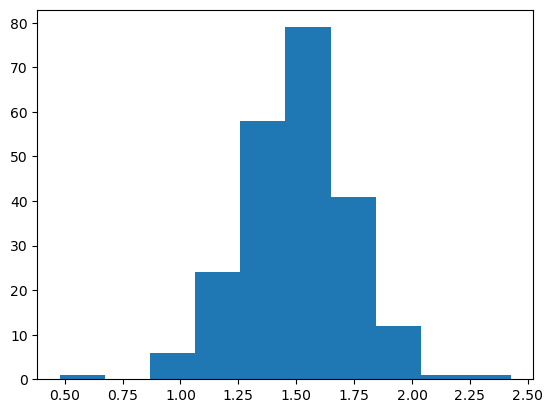

In [23]:
plt.hist(dhi)

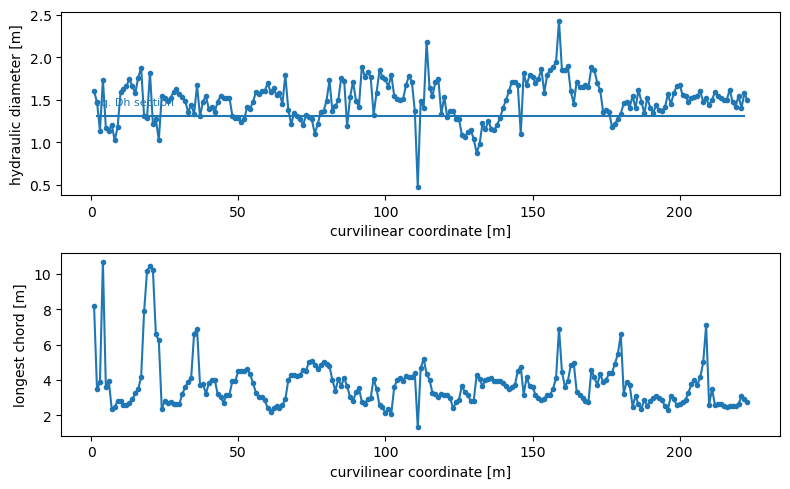

In [24]:

fig, (ax, axchords) = plt.subplots(2, 1, figsize = (8, 5))

ax.plot(curvilinear_coords, dhi, "-o", markersize=3)


#plt.plot(curvilinear_coords[1:-1], [elem["hydraulic_diameter"] for elem in descriptors][1:], label = "hydraulic_diameter")
ax.axhline(equivalent_dh(dhi[1:], li), ls = "-", xmin=0.05, xmax=0.95)

ax.text(1,equivalent_dh(dhi[1:], li)*1.1, "eq. Dh section", color = "C0", fontsize = 8)

ax.set_xlabel("curvilinear coordinate [m]")
ax.set_ylabel("hydraulic diameter [m]")


axchords.plot(curvilinear_coords, max_chords, "-o", markersize=3)
axchords.set_xlabel("curvilinear coordinate [m]")
axchords.set_ylabel("longest chord [m]")

plt.tight_layout()
plt.savefig(f"./temp/test_hydraulic_diameters.png")